# Japanese Used-Car Fair Price Estimator — Professional EDA

## Business objective

This notebook prepares the dataset for a production application whose main user question is:

> **“What is my car worth in the current Japanese used-car listing market?”**

The ML target is **`vehicle_price_jpy`**, which represents the advertised vehicle price. The model is intended to estimate a **fair listing-market value**, not a guaranteed transaction price, trade-in price, auction price, or dealer purchase price.

### Intended production interaction

A user will enter a small set of vehicle attributes such as manufacturer, model, year, mileage, fuel, transmission, drivetrain, repair history, and prefecture. The backend will clean those values, engineer additional features, and send them to the model.

### What this EDA must establish

1. Whether the scraped data is suitable for this business case.
2. Which rows are trustworthy enough for training.
3. Which columns are safe to use without target leakage.
4. How Japanese categorical values should be handled.
5. Which anomalies and missing values need explicit treatment.
6. Which inputs should become part of the production feature contract.

The notebook deliberately separates **raw scraped data**, **business interpretation**, and **model-ready features**.

## 1. Environment and reproducibility

The code below imports only standard data-science packages for EDA.  
The dataset path is resolved in this place:

- `used_cars_japan.csv` in the same directory as this notebook


In [4]:
from pathlib import Path
import warnings
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# Make notebook output easier to read.
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42

# Resolve the dataset path in a portable way.
LOCAL_PATH = Path("../data/raw/japan-cars-csv_new.csv") if Path.cwd().name == "notebook" else Path("data/raw/japan-cars-csv_new.csv")

if LOCAL_PATH.exists():
    DATA_PATH = LOCAL_PATH
else:
    raise FileNotFoundError(
        "Place 'japan-cars-csv_new.csv' next to this notebook or update DATA_PATH."
    )

print(f"Using dataset: {DATA_PATH.resolve()}")

Using dataset: /Users/mohamedaldofani/ML_Project/data/raw/japan-cars-csv_new.csv


## 2. Load the raw scrape

`low_memory=False` is used because a few scraped columns contain mixed representations.  
We do **not** force types immediately because type inconsistency is itself a useful data-quality signal during EDA.

In [5]:
df_raw = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Rows:    {len(df_raw):,}")
print(f"Columns: {df_raw.shape[1]:,}")
display(df_raw.head(3))

Rows:    104,991
Columns: 44


,schema_version,parser_version,source,listing_id,listing_url,collected_at,source_updated_date,title,manufacturer,model,trim,model_code,registration_year,registration_month,mileage_km,mileage_status,vehicle_price_jpy,total_price_jpy,fees_jpy,currency,price_basis,transmission,drivetrain,fuel,engine_cc,body_type,color,repair_history,shaken_expiry_month,shaken_status,prefecture,seller_name,seller_url,doors,seats,steering,one_owner,non_smoking,service_records,unused_vehicle,raw_sha256,quality_status,quality_flags,raw_attributes_json
0,1.00,2026.09.18.1,carsensor,AU0012149608,https://www.carsensor.net/usedcar/detail/AU001...,2026-09-20T07:05:34+00:00,NaN,シトロエン C5 c5ディーゼルターボ,シトロエン,C5,c5ディーゼルターボ,NaN,"2,017.00",NaN,"74,000.00",reported,"2,380,000.00","2,580,000.00","200,000.00",JPY,advertised_vehicle_price,フロア6AT,2WD,ディーゼル,"2,000.00",セダン,シルバー,False,NaN,車検残:無(購入時に新規取得) 車検の取得にあたって必要な費用(自動車重量税、自賠責保険料な...,東京都,JAVEL,https://www.carsensor.net/shop/tokyo/301244001...,4.00,5.00,右,NaN,NaN,NaN,NaN,ed9657f8970ae36df44be746a76e49db327964fcbb0eed...,ready,NaN,"{""年式(製造年)"": ""2017(H29)"", ""ワンオーナー"": ""-"", ""走行距離""..."
1,1.00,2026.09.18.1,carsensor,AU0055978615,https://www.carsensor.net/usedcar/detail/AU005...,2026-09-21T13:34:52+00:00,NaN,日産 スカイラインGT-R 2.6 4WD R33後期リップスポイラー Veilsideマフラー,日産,スカイラインGT-R,2.6 4WD,NaN,"1,996.00",NaN,"124,000.00",reported,NaN,NaN,NaN,JPY,advertised_vehicle_price,フロア5MT,4WD,ガソリン,"2,600.00",クーペ,KN6ダークグレーパール,False,NaN,車検残:無(購入時に新規取得) 車検の取得にあたって法定費用(自動車重量税、自賠責保険料など...,富山県,ウイングトゥーワン,https://www.carsensor.net/shop/toyama/04319000...,2.00,4.00,右,NaN,NaN,NaN,NaN,1d091d13bfde5a33350db6e6d042ce1ce10b3e45fa3b00...,review,missing_vehicle_price_jpy,"{""年式(初度登録年)"": ""1996(H08)"", ""ワンオーナー"": ""-"", ""走行距..."
2,1.00,2026.09.18.1,carsensor,AU0074675938,https://www.carsensor.net/usedcar/detail/AU007...,2026-09-20T04:59:02+00:00,NaN,トヨタ センチュリー BBS20AW ローダウン 本革シート,トヨタ,センチュリー,BBS20AW ローダウン 本革シート,NaN,"2,020.00",NaN,"13,000.00",reported,NaN,NaN,NaN,JPY,advertised_vehicle_price,その他AT,2WD,ハイブリッド,"5,000.00",セダン,ブラック,False,2027-06,2027(R09)年6月,愛媛県,株式会社ASホールディングス,NaN,4.00,5.00,右,True,NaN,NaN,NaN,0852c6f39699e7ac8f1b4e2d9b7fe11a446023e510bd75...,review,missing_vehicle_price_jpy,"{""年式(初度登録年)"": ""2020(R02)"", ""ワンオーナー"": ""◯"", ""走行距..."


## 3. Dataset schema and high-level audit

For each column we calculate:

- pandas dtype,
- missing count and percentage,
- number of distinct non-null values.

This immediately reveals fully empty fields, high-cardinality categoricals, and fields that may require normalization.

In [6]:
schema = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_n": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "n_unique": df_raw.nunique(dropna=True),
}).sort_values(["missing_pct", "n_unique"], ascending=[False, False])

display(schema)

,dtype,missing_n,missing_pct,n_unique
model_code,float64,104991,100.00,0
registration_month,float64,104991,100.00,0
unused_vehicle,object,103171,98.27,1
quality_flags,str,100128,95.37,8
one_owner,object,88197,84.00,1
service_records,object,84615,80.59,1
source_updated_date,str,79743,75.95,144
non_smoking,object,54087,51.52,1
shaken_expiry_month,str,45543,43.38,40
seller_url,str,10490,9.99,71675


### Important interpretation

A missing value does not always mean the same thing.

For example, fields such as `one_owner`, `non_smoking`, `service_records`, and `unused_vehicle` may be populated only when a listing explicitly advertises that property. In that situation, null often means **“not stated / unknown”**, not automatically `False`.

That distinction should be preserved in production preprocessing.

In [7]:
flag_like_columns = [
    "one_owner",
    "non_smoking",
    "service_records",
    "unused_vehicle",
    "repair_history",
]

for col in flag_like_columns:
    if col in df_raw.columns:
        print(f"\n--- {col} ---")
        display(df_raw[col].value_counts(dropna=False).head(10))


--- one_owner ---


one_owner
NaN     88197
True    16794
Name: count, dtype: int64


--- non_smoking ---


non_smoking
NaN     54087
True    50904
Name: count, dtype: int64


--- service_records ---


service_records
NaN     84615
True    20376
Name: count, dtype: int64


--- unused_vehicle ---


unused_vehicle
NaN     103171
True      1820
Name: count, dtype: int64


--- repair_history ---


repair_history
False    100863
True       4128
Name: count, dtype: int64

## 4. Snapshot coverage, sources, and duplicates

This scrape is a market snapshot. Before modeling, we verify:

- which marketplaces are represented,
- the collection period,
- whether listing IDs are duplicated,
- whether raw-content hashes are duplicated.

A short snapshot is appropriate for **current-market price estimation**, but it is not enough to model time-to-sale or depreciation over time.

In [8]:
print("Source counts:")
display(df_raw["source"].value_counts(dropna=False).to_frame("rows"))

collected = pd.to_datetime(df_raw["collected_at"], errors="coerce", utc=True)
print(f"Collection start: {collected.min()}")
print(f"Collection end:   {collected.max()}")

print(f"Duplicate listing_id rows: {df_raw.duplicated('listing_id').sum():,}")
print(f"Duplicate raw_sha256 rows: {df_raw.duplicated('raw_sha256').sum():,}")

Source counts:


,rows
source,
carsensor,79743
goo-net,25248


Collection start: 2026-09-18 14:43:25+00:00
Collection end:   2026-09-24 06:10:04+00:00
Duplicate listing_id rows: 0
Duplicate raw_sha256 rows: 0


## 5. Quality-status audit

The scraper already provides `quality_status` and `quality_flags`. We treat those as useful first-pass checks, not as a complete guarantee that a row is economically plausible.

For model training, the recommended starting population is `quality_status == "ready"`, followed by additional domain validation.

In [9]:
display(df_raw["quality_status"].value_counts(dropna=False).to_frame("rows"))

print("\nMost common quality flags:")
display(df_raw["quality_flags"].value_counts(dropna=False).head(15).to_frame("rows"))

,rows
quality_status,
ready,100128
review,4863



Most common quality flags:


,rows
quality_flags,
NaN,100128
missing_vehicle_price_jpy,4180
missing_mileage_km,402
missing_mileage_km|missing_vehicle_price_jpy,241
missing_registration_year,24
missing_registration_year|missing_mileage_km,8
missing_registration_year|missing_mileage_km|missing_vehicle_price_jpy,4
missing_registration_year|missing_vehicle_price_jpy,2
missing_manufacturer,2


## 6. Target definition and leakage checks

The production target is:

**`vehicle_price_jpy` = advertised vehicle price**

We explicitly test whether other price fields are deterministic transformations of the target.

If `total_price_jpy = vehicle_price_jpy + fees_jpy`, then using `total_price_jpy` or `fees_jpy` as model inputs would leak information unavailable to a genuine valuation model.

In [10]:
price_cols = ["vehicle_price_jpy", "fees_jpy", "total_price_jpy"]
complete_price_mask = df_raw[price_cols].notna().all(axis=1)

price_identity_error = (
    df_raw.loc[complete_price_mask, "vehicle_price_jpy"]
    + df_raw.loc[complete_price_mask, "fees_jpy"]
    - df_raw.loc[complete_price_mask, "total_price_jpy"]
)

print(f"Rows with all price components: {complete_price_mask.sum():,}")
print(f"Maximum absolute identity error: {price_identity_error.abs().max():,.0f} JPY")
print(f"Exact identity rate: {(price_identity_error == 0).mean():.2%}")

Rows with all price components: 100,564
Maximum absolute identity error: 0 JPY
Exact identity rate: 100.00%


### Leakage rule

For a model predicting `vehicle_price_jpy`, exclude:

- `total_price_jpy`
- `fees_jpy`
- raw listing titles if they may contain prices
- URLs / IDs / hashes / parser metadata
- fields generated after or from the pricing decision

The `title` field is useful for future NLP work, but should not enter Version 1 because scraped titles can literally contain a price.

In [11]:
LEAKAGE_OR_METADATA_COLUMNS = [
    "vehicle_price_jpy",  # target itself
    "total_price_jpy",
    "fees_jpy",
    "title",
    "listing_id",
    "listing_url",
    "seller_url",
    "raw_sha256",
    "raw_attributes_json",
    "schema_version",
    "parser_version",
    "quality_status",
    "quality_flags",
    "currency",
    "price_basis",
]

print("Columns intentionally excluded from the first production model:")
for col in LEAKAGE_OR_METADATA_COLUMNS:
    print(" -", col)

Columns intentionally excluded from the first production model:
 - vehicle_price_jpy
 - total_price_jpy
 - fees_jpy
 - title
 - listing_id
 - listing_url
 - seller_url
 - raw_sha256
 - raw_attributes_json
 - schema_version
 - parser_version
 - quality_status
 - quality_flags
 - currency
 - price_basis


## 7. Target distribution and price sanity checks

Used-car prices are strongly right-skewed: normal passenger cars and kei cars coexist with luxury, performance, and commercial vehicles.

We inspect both the raw price distribution and `log1p(price)`. A logarithmic view is important because a difference of ¥500,000 has very different meaning for a ¥700,000 car and a ¥20,000,000 car.

,vehicle_price_jpy
count,"100,128.00"
mean,"2,292,584.34"
std,"2,227,405.83"
min,48.00
0.1%,"100,000.00"
0.5%,"170,000.00"
1%,"200,000.00"
5%,"350,000.00"
25%,"980,000.00"
50%,"1,738,000.00"


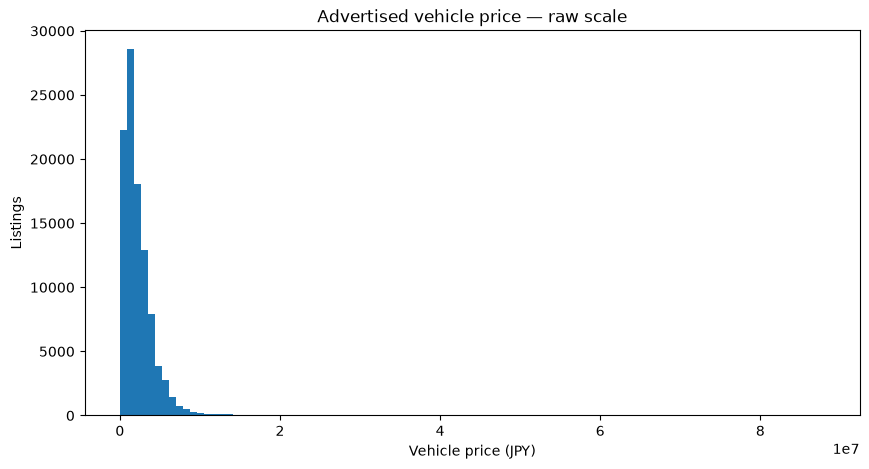

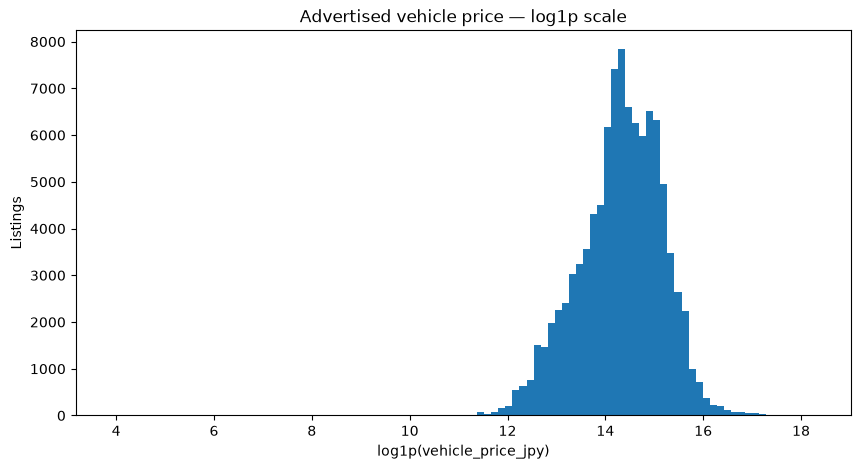

In [12]:
ready = df_raw.loc[
    (df_raw["quality_status"] == "ready")
    & df_raw["vehicle_price_jpy"].notna()
].copy()

price = ready["vehicle_price_jpy"].astype(float)

display(
    price.describe(
        percentiles=[0.001, 0.005, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.995, 0.999]
    ).to_frame("vehicle_price_jpy")
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(price, bins=100)
ax.set_title("Advertised vehicle price — raw scale")
ax.set_xlabel("Vehicle price (JPY)")
ax.set_ylabel("Listings")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(np.log1p(price), bins=100)
ax.set_title("Advertised vehicle price — log1p scale")
ax.set_xlabel("log1p(vehicle_price_jpy)")
ax.set_ylabel("Listings")
plt.show()

### Inspect suspicious extremes instead of deleting them blindly

Statistical outliers can be legitimate Ferraris, buses, trucks, or classic cars.  
The correct process is:

1. inspect the lowest/highest examples,
2. distinguish valid rare vehicles from parsing errors,
3. encode explicit validation rules,
4. document every exclusion.

The model-training notebook uses a conservative configurable lower bound (`¥30,000`) to protect against obvious parsing failures while retaining genuinely inexpensive listings.

In [13]:
columns_to_show = [
    "source",
    "title",
    "manufacturer",
    "model",
    "registration_year",
    "mileage_km",
    "vehicle_price_jpy",
    "fees_jpy",
    "total_price_jpy",
]

print("Lowest advertised prices:")
display(ready.nsmallest(15, "vehicle_price_jpy")[columns_to_show])

print("\nHighest advertised prices:")
display(ready.nlargest(15, "vehicle_price_jpy")[columns_to_show])

Lowest advertised prices:


,source,title,manufacturer,model,registration_year,mileage_km,vehicle_price_jpy,fees_jpy,total_price_jpy
73829,carsensor,スズキ ワゴンR 660 FX キーレスエントリー アイドリングストップ オートエアコン 電...,スズキ,ワゴンR,"2,014.00","46,000.00",48.00,"529,952.00","530,000.00"
17470,carsensor,ミニ ミニクラブマン クーパーS,ミニ,ミニクラブマン,"2,008.00","99,000.00",65.00,"779,935.00","780,000.00"
3872,carsensor,メルセデス・ベンツ 190クラス 190E 2.5-16 ディーラー車,メルセデス・ベンツ,190クラス,"1,990.00","160,000.00",583.00,"5,999,417.00","6,000,000.00"
71133,carsensor,日産 モコ 660 E 禁煙車 スマートキー ナビ TV ETC AAC ABS 電動格納ド...,日産,モコ,"2,010.00","99,000.00","30,000.00","100,000.00","130,000.00"
83156,goo-net,ダイハツ ムーヴ L キーレス 社外アルミホイール フルフラット ベンチーシート 衝突安全ボ...,ダイハツ,ムーヴ,"2,006.00","29,000.00","38,000.00","50,000.00","88,000.00"
3182,carsensor,ダイハツ タントエグゼ 660 G ワンセグTV ナビ,ダイハツ,タントエグゼ,"2,010.00","160,000.00","42,000.00","96,000.00","138,000.00"
73787,carsensor,ダイハツ ムーヴコンテ 660 X 4WD 車検R9年3月3日 スマートキー キーフリー 純...,ダイハツ,ムーヴコンテ,"2,010.00","140,000.00","48,000.00","30,000.00","78,000.00"
82279,goo-net,ダイハツ ムーヴコンテ X 4WD 車検R9年3月3日 スマートキー キーフリー 純正オーデ...,ダイハツ,ムーヴコンテ,"2,010.00","142,000.00","48,000.00","30,000.00","78,000.00"
83014,goo-net,日産 デイズ ハイウェイスター X ユーザー買取車/純正ナビ/ブルートゥース接続/バックカメ...,日産,デイズ,"2,013.00","194,000.00","49,000.00","100,000.00","149,000.00"
73261,carsensor,ホンダ フィット 1.3 G ハイウェイエディション Tチェーン SDフルセグナビ Blue...,ホンダ,フィット,"2,008.00","114,000.00","50,000.00","79,000.00","129,000.00"



Highest advertised prices:


,source,title,manufacturer,model,registration_year,mileage_km,vehicle_price_jpy,fees_jpy,total_price_jpy
3981,carsensor,ランボルギーニ レヴエルト 6.5 4WD 6.5 4WD Giallo Belenus O...,ランボルギーニ,レヴエルト,"2,025.00",86.00,"88,000,000.00","200,000.00","88,200,000.00"
1016,carsensor,フェラーリ SF90ストラダーレ アセット フィオラノ F1 DCT E4WD レーシングシ...,フェラーリ,SF90ストラダーレ,"2,022.00",535.00,"69,800,000.00","180,000.00","69,980,000.00"
1328,carsensor,ランボルギーニ ウルス ペルフォルマンテ 4WD ダークパッケージ 4-Seat アンビエン...,ランボルギーニ,ウルス,"2,024.00",550.00,"68,800,000.00","755,000.00","69,555,000.00"
1932,carsensor,フェラーリ 812GTS F1 DCT 認定中古車 20インチ鍛造ダイヤモンドカットホイール...,フェラーリ,812GTS,"2,021.00","3,000.00","67,800,000.00","440,000.00","68,240,000.00"
18050,carsensor,日産 スカイラインGT-R 2.6 VスペックII ニュル 4WD,日産,スカイラインGT-R,"2,002.00","14,000.00","64,800,000.00","200,000.00","65,000,000.00"
38,carsensor,ランボルギーニ アヴェンタドール S 4WD パワクラマフラー/DMCリアスポ/ローダウン/...,ランボルギーニ,アヴェンタドール,"2,020.00","6,000.00","54,800,000.00","155,000.00","54,955,000.00"
6207,carsensor,フェラーリ SF90ストラダーレ アセット フィオラノ F1 DCT E4WD Ferrar...,フェラーリ,SF90ストラダーレ,"2,022.00",274.00,"49,000,000.00","400,000.00","49,400,000.00"
14325,carsensor,日産 GT-R 3.8 NISMO 4WD GT-R NISMO スペシャルエディション 4...,日産,GT-R,"2,021.00",3.00,"46,500,000.00","280,000.00","46,780,000.00"
7246,carsensor,ランボルギーニ ウルス ペルフォルマンテ 左H パノラマルーフ ナイトビジョン 22AW O...,ランボルギーニ,ウルス,"2,023.00","2,000.00","45,900,000.00","510,000.00","46,410,000.00"
1015,carsensor,フェラーリ F8トリブート F1 DCT レーシングシート ディーラー車 OP1185,フェラーリ,F8トリブート,"2,022.00","1,000.00","45,800,000.00","180,000.00","45,980,000.00"


## 8. Numeric feature audit

We inspect values that are especially prone to scraping problems:

- registration year,
- mileage,
- engine displacement,
- seats,
- doors.

Extreme values are not automatically wrong. A 75-seat bus is possible; a 75-seat hatchback is not. Domain checks should therefore consider vehicle segment where possible.

In [14]:
numeric_cols = [
    "registration_year",
    "mileage_km",
    "engine_cc",
    "doors",
    "seats",
    "vehicle_price_jpy",
]

display(
    ready[numeric_cols].describe(
        percentiles=[0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999]
    ).T
)

,count,mean,std,min,0.1%,1%,5%,50%,95%,99%,99.9%,max
registration_year,"100,128.00","2,019.19",5.58,"1,944.00","1,986.00","2,001.00","2,010.00","2,020.00","2,026.00","2,026.00","2,026.00","2,026.00"
mileage_km,"100,128.00","48,867.54","46,811.29",1.00,3.00,5.00,10.00,"40,000.00","124,000.00","183,000.00","480,000.00","999,000.00"
engine_cc,"99,326.00","1,580.48","1,063.17",1.00,650.00,660.00,660.00,"1,500.00","3,000.00","4,400.00","9,625.25","85,000.00"
doors,"97,911.00",4.73,0.73,2.00,2.00,2.00,3.00,5.00,5.00,5.00,5.00,5.00
seats,"99,480.00",4.90,1.36,1.00,2.00,2.00,4.00,5.00,7.00,8.00,10.00,55.00
vehicle_price_jpy,"100,128.00","2,292,584.34","2,227,405.83",48.00,"100,000.00","200,000.00","350,000.00","1,738,000.00","5,770,000.00","9,447,300.00","24,731,730.00","88,000,000.00"


In [15]:
# Display a few rows with unusually large engine displacement or seating capacity.
print("Largest engine_cc values:")
display(
    ready.nlargest(15, "engine_cc")[
        ["manufacturer", "model", "body_type", "fuel", "engine_cc", "vehicle_price_jpy"]
    ]
)

print("\nLargest seat counts:")
display(
    ready.nlargest(15, "seats")[
        ["manufacturer", "model", "body_type", "seats", "vehicle_price_jpy"]
    ]
)

Largest engine_cc values:


,manufacturer,model,body_type,fuel,engine_cc,vehicle_price_jpy
41267,日産,リーフ,ハッチバック,電気,"85,000.00","1,419,000.00"
26318,日産,リーフ,ハッチバック,電気,"70,000.00","615,000.00"
2858,アウディ,Q8スポーツバックe-tron,クロカン・SUV,その他,"65,000.00","5,980,000.00"
4163,アウディ,e-tron,クロカン・SUV,その他,"65,000.00","4,580,000.00"
9666,トヨタ,MIRAI,セダン,その他,"48,000.00","3,050,000.00"
2430,アバルト,アバルト500eカブリオレ,その他,電気,"47,000.00","4,730,000.00"
16423,いすゞ,ギガ,トラック,ディーゼル,"22,800.00","3,620,000.00"
79374,三菱ふそう,スーパーグレート,トラック,ディーゼル,"21,200.00","7,480,000.00"
312,三菱ふそう,スーパーグレート,トラック,ディーゼル,"20,080.00","6,000,000.00"
45899,日野自動車,プロフィア,トラック,ディーゼル,"19,680.00","6,980,000.00"



Largest seat counts:


,manufacturer,model,body_type,seats,vehicle_price_jpy
5655,ホンダ,レジェンド,セダン,55.00,"1,580,000.00"
13890,マツダ,CX-30,クロカン・SUV,50.00,"2,298,000.00"
10714,ダイハツ,ムーヴ,セダン,45.00,"189,000.00"
45517,日野自動車,メルファ,その他,42.00,"8,700,000.00"
4483,三菱ふそう,エアロミディ,その他,35.00,"1,850,000.00"
2121,日野自動車,ポンチョ,その他,31.00,"2,550,000.00"
4241,日産,シビリアン,その他,31.00,"2,080,000.00"
1225,トヨタ,コースター,その他,29.00,"4,950,000.00"
6525,トヨタ,コースター,その他,29.00,"8,300,000.00"
9625,三菱ふそう,ローザ,オープン,29.00,"6,600,000.00"


## 9. Missingness analysis

Missingness itself can carry information, but production behavior must be intentional.

For the app:

- mandatory fields should be validated before prediction,
- optional fields should map to an explicit `__UNKNOWN__` category,
- we should never silently convert “not stated” into `False`.

,missing_pct
model_code,100.00
registration_month,100.00
unused_vehicle,98.27
quality_flags,95.37
one_owner,84.00
service_records,80.59
source_updated_date,75.95
non_smoking,51.52
shaken_expiry_month,43.38
seller_url,9.99


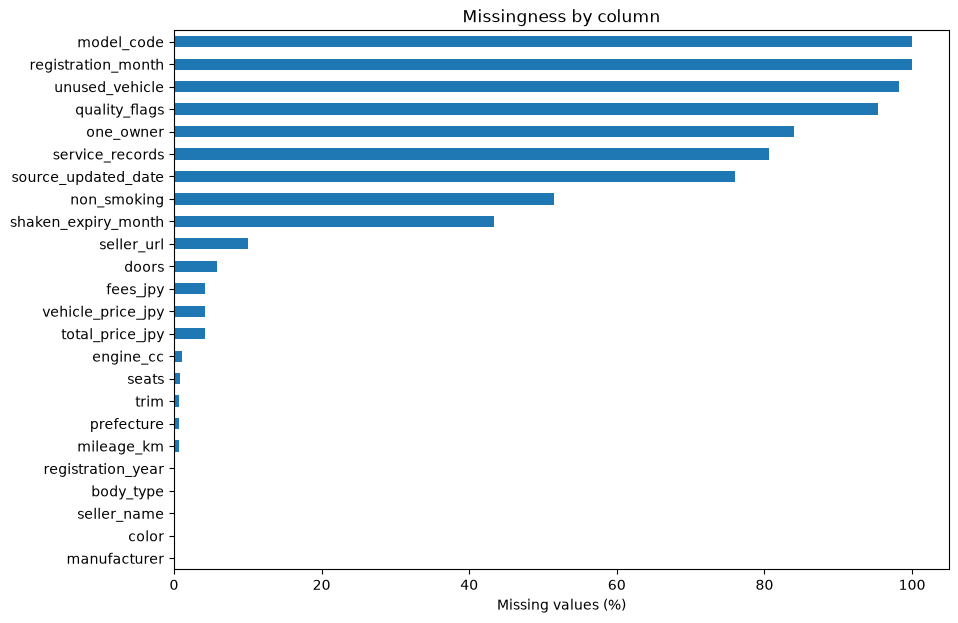

In [16]:
missing = (
    df_raw.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("missing_pct")
)

display(missing.to_frame())

fig, ax = plt.subplots(figsize=(10, 7))
missing[missing > 0].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Missingness by column")
ax.set_xlabel("Missing values (%)")
plt.show()

## 10. Cardinality analysis

CatBoost is a strong candidate because this dataset contains many high-cardinality categorical fields such as model, trim, seller, and color.

However, the production model should use only fields that are either:

- entered by the user,
- reliably inferred from user choices, or
- supplied by a trusted backend enrichment service.

We intentionally avoid `seller_name` in the first model because a person asking “what is my car worth?” should not need to choose a dealer.

In [17]:
categorical_cols = df_raw.select_dtypes(include=["object", "string"]).columns.tolist()

cardinality = (
    df_raw[categorical_cols]
    .nunique(dropna=True)
    .sort_values(ascending=False)
    .rename("n_unique")
)

display(cardinality.to_frame())

/var/folders/jr/774359wn5tg3ddwfx4sd5y5r0000gn/T/ipykernel_78487/5898467.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_raw.select_dtypes(include=["object"]).columns.tolist()


,n_unique
raw_sha256,104991
listing_id,104991
listing_url,104991
raw_attributes_json,104912
collected_at,104568
title,94856
seller_url,71675
trim,12339
seller_name,10227
color,6090


## 11. normalize Japanese text strategy

The model does **not** need Japanese categories translated into English.  
For example, CatBoost can treat `トヨタ` and `アルファード` as valid categorical tokens.

The important requirement is **consistency**.

so we will do this approach:

- keep the original Japanese value for traceability,
- Unicode-normalize and clean whitespace,
- create canonical features for categories with obvious synonyms,
- optionally create English labels only for UI/display.

For example, `ディーゼル` and `軽油` should both map to a canonical `diesel` category.

In [18]:
def normalize_text(value):
    """Normalize scraped categorical text without changing its semantic identity."""
    if pd.isna(value):
        return "__UNKNOWN__"

    text = unicodedata.normalize("NFKC", str(value)).strip()
    text = re.sub(r"\s+", " ", text)

    placeholders = {"", "-", "−", "'-", "不明", "nan", "None"}
    return "__UNKNOWN__" if text in placeholders else text


def normalize_fuel(value):
    """Collapse Japanese fuel synonyms into stable machine categories."""
    text = normalize_text(value)

    if text == "__UNKNOWN__":
        return text
    if "プラグイン" in text and "ハイブリッド" in text:
        return "phev"
    if "電気" in text or "EV" in text.upper():
        return "electric"
    if "ディーゼル" in text or "軽油" in text:
        return "diesel"
    if "ハイブリッド" in text:
        return "hybrid"
    if "ガソリン" in text:
        return "gasoline"
    if "水素" in text:
        return "hydrogen"
    return "other"


fuel_example = (
    df_raw[["fuel"]]
    .drop_duplicates()
    .assign(fuel_clean=lambda x: x["fuel"].map(normalize_fuel))
    .sort_values(["fuel_clean", "fuel"])
)

display(fuel_example)

,fuel,fuel_clean
7434,'-,__UNKNOWN__
0,ディーゼル,diesel
79770,軽油,diesel
152,電気,electric
79799,電気自動車(EV),electric
1,ガソリン,gasoline
2,ハイブリッド,hybrid
80512,水素,hydrogen
84551,CNG,other
232,その他,other


## 12. Transmission engineering

The raw transmission column contains detailed Japanese strings such as shifter location, manual mode, gear count, CVT, AT, and MT.

For production we can preserve the raw string while extracting simpler derived features:

- simplified transmission family,
- number of gears when stated,
- whether an automatic transmission advertises manual mode.

This reduces fragmentation while retaining useful information.

In [19]:
def normalize_transmission(value):
    """Map many scraped transmission descriptions into stable families."""
    text = normalize_text(value).upper()

    if text == "__UNKNOWN__":
        return text
    if "CVT" in text:
        return "CVT"
    if "DCT" in text:
        return "DCT"
    # Check AT before generic MT because 'MTモード付AT' is still an automatic.
    if "AT" in text:
        return "AT"
    if "MT" in text:
        return "MT"
    return "other"


def extract_gear_count(value):
    """Extract values such as 6 from '6AT', '6MT', or Japanese '6速'."""
    text = normalize_text(value).upper()

    if text == "__UNKNOWN__":
        return np.nan

    match = re.search(r"(\d+)\s*(?:AT|MT|速)", text)
    return float(match.group(1)) if match else np.nan


transmission_example = (
    df_raw["transmission"]
    .value_counts(dropna=False)
    .head(30)
    .rename_axis("transmission")
    .reset_index(name="rows")
)

transmission_example["transmission_simple"] = transmission_example["transmission"].map(
    normalize_transmission
)
transmission_example["gear_count"] = transmission_example["transmission"].map(
    extract_gear_count
)

display(transmission_example)

,transmission,rows,transmission_simple,gear_count
0,インパネCVT,25152,CVT,NaN
1,インパネAT,9273,AT,NaN
2,フロアCVT,9259,CVT,NaN
3,CVT,9222,CVT,NaN
4,その他AT,6645,AT,NaN
5,フロアMTモード付CVT,4865,CVT,NaN
6,インパネMTモード付CVT,3331,CVT,NaN
7,フロアMTモード付6AT,3326,AT,6.00
8,フロア6MT,2857,MT,6.00
9,フロア5MT,2779,MT,5.00


## 13. Relationship between price, age, and mileage

These are expected to be among the strongest predictors.

We derive:

- `vehicle_age`: years between the market snapshot and registration year,
- `log_mileage`: stabilizes the heavily skewed mileage distribution,
- `km_per_year`: distinguishes a young high-mileage car from an old low-mileage car.

Because this snapshot is from 2026, the exploratory reference year is 2026.  
The trained model should be retrained as the market moves forward rather than assumed to remain permanently valid.

In [20]:
EDA_REFERENCE_YEAR = int(collected.dt.year.mode().iloc[0])

eda = ready.copy()
eda["vehicle_age"] = (
    EDA_REFERENCE_YEAR - pd.to_numeric(eda["registration_year"], errors="coerce")
).clip(lower=0)

eda["mileage_km"] = pd.to_numeric(eda["mileage_km"], errors="coerce")
eda["log_mileage"] = np.log1p(eda["mileage_km"].clip(lower=0))
eda["km_per_year"] = eda["mileage_km"] / eda["vehicle_age"].clip(lower=1)

print(f"EDA reference year: {EDA_REFERENCE_YEAR}")
display(
    eda[["vehicle_age", "mileage_km", "log_mileage", "km_per_year"]]
    .describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])
    .T
)

EDA reference year: 2026


,count,mean,std,min,1%,5%,50%,95%,99%,max
vehicle_age,"100,128.00",6.81,5.58,0.00,0.00,0.00,6.00,16.00,25.00,82.00
mileage_km,"100,128.00","48,867.54","46,811.29",1.00,5.00,10.00,"40,000.00","124,000.00","183,000.00","999,000.00"
log_mileage,"100,128.00",9.81,2.44,0.69,1.79,2.40,10.60,11.73,12.12,13.81
km_per_year,"100,128.00","7,171.64","6,311.51",0.50,4.00,10.00,"6,500.00","16,000.00","24,091.25","690,000.00"


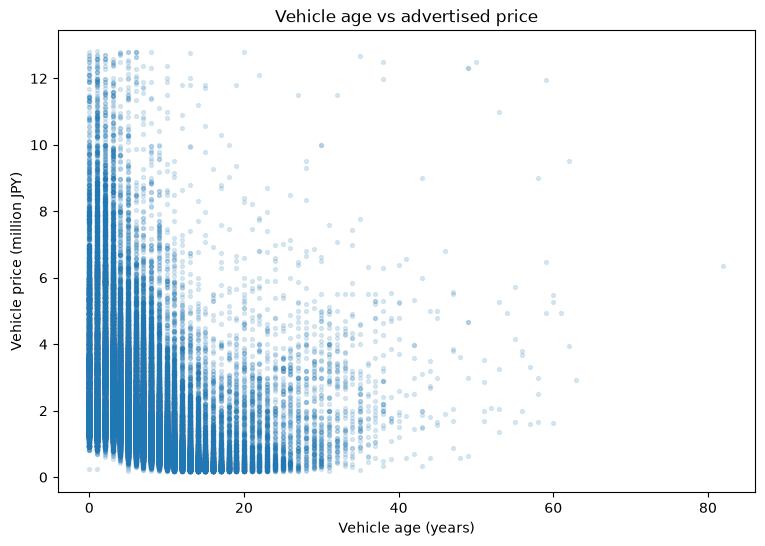

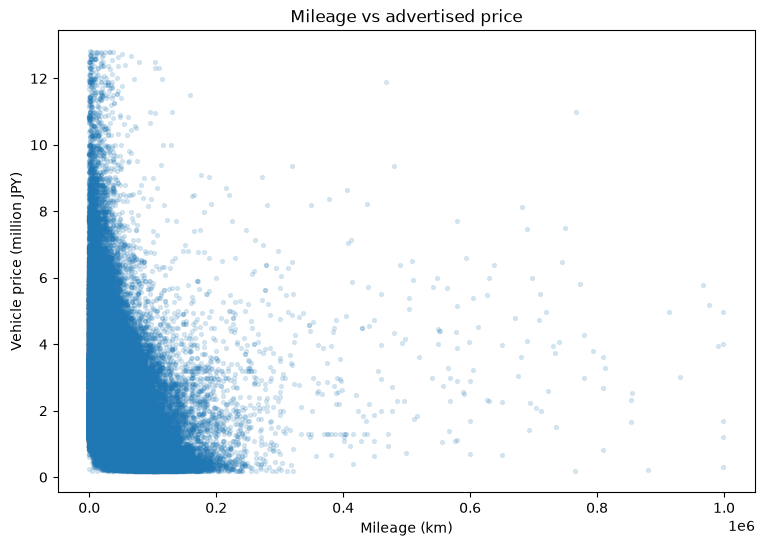

In [21]:
# To avoid a few extreme vehicles visually flattening the plots,
# the charts use only the central 99% of the relevant variables.
plot_df = eda[
    eda["vehicle_price_jpy"].between(
        eda["vehicle_price_jpy"].quantile(0.005),
        eda["vehicle_price_jpy"].quantile(0.995),
    )
].copy()

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    plot_df["vehicle_age"],
    plot_df["vehicle_price_jpy"] / 1_000_000,
    s=8,
    alpha=0.15,
)
ax.set_title("Vehicle age vs advertised price")
ax.set_xlabel("Vehicle age (years)")
ax.set_ylabel("Vehicle price (million JPY)")
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    plot_df["mileage_km"],
    plot_df["vehicle_price_jpy"] / 1_000_000,
    s=8,
    alpha=0.15,
)
ax.set_title("Mileage vs advertised price")
ax.set_xlabel("Mileage (km)")
ax.set_ylabel("Vehicle price (million JPY)")
plt.show()

## 14. Categorical market structure

A raw average price by manufacturer or model is **descriptive**, not causal.  
Different brands have different model mixes, years, mileage, and vehicle segments.

For each category, it is more informative to display:

- listing count,
- median price,
- median registration year,
- median mileage.

The median is used because used-car price distributions are highly skewed.

In [22]:
def category_summary(data, column, min_count=30, top_n=25):
    """Summarize category size and typical vehicle characteristics."""
    summary = (
        data.groupby(column, dropna=False)
        .agg(
            listings=("vehicle_price_jpy", "size"),
            median_price_jpy=("vehicle_price_jpy", "median"),
            median_year=("registration_year", "median"),
            median_mileage_km=("mileage_km", "median"),
        )
        .query("listings >= @min_count")
        .sort_values("listings", ascending=False)
        .head(top_n)
    )
    return summary


for col in ["manufacturer", "model", "fuel", "body_type", "drivetrain", "prefecture"]:
    print(f"\n### {col}")
    display(category_summary(eda, col))


### manufacturer


,listings,median_price_jpy,median_year,median_mileage_km
manufacturer,,,,
トヨタ,29944,"2,688,000.00","2,021.00","39,000.00"
スズキ,12829,"1,248,000.00","2,021.00","33,000.00"
ホンダ,12302,"1,447,000.00","2,020.00","39,000.00"
ダイハツ,10407,"921,000.00","2,019.00","46,000.00"
日産,10354,"1,290,000.00","2,019.00","46,000.00"
マツダ,4237,"1,837,000.00","2,020.00","46,000.00"
スバル,3236,"1,589,000.00","2,018.00","55,000.00"
三菱,2931,"1,779,000.00","2,022.00","32,000.00"
レクサス,2852,"3,754,000.00","2,019.00","45,000.00"



### model


,listings,median_price_jpy,median_year,median_mileage_km
model,,,,
N-BOX,2646,"1,150,000.00","2,020.00","42,000.00"
タント,2563,"973,000.00","2,019.00","50,000.00"
プリウス,2271,"1,850,000.00","2,019.00","48,000.00"
アルファード,2236,"4,269,500.00","2,021.00","36,000.00"
スペーシア,2014,"1,295,000.00","2,022.00","22,000.00"
セレナ,1938,"1,980,000.00","2,019.00","50,000.00"
ハスラー,1811,"1,299,000.00","2,021.00","31,000.00"
ハリアー,1701,"3,198,000.00","2,021.00","38,000.00"
ヴォクシー,1672,"2,898,500.00","2,021.00","43,500.00"



### fuel


...

,listings,median_price_jpy,median_year,median_mileage_km
body_type,,,,
ハッチバック,33570,"1,020,000.00","2,019.00","47,000.00"
クロカン・SUV,19915,"2,676,000.00","2,022.00","31,000.00"
ミニバン,11551,"2,882,000.00","2,021.00","42,000.00"
軽-RV系,6443,"1,318,000.00","2,021.00","27,000.00"
セダン,6036,"2,372,500.00","2,018.00","53,000.00"
SUV・クロスカントリー・ライトクロカン,5852,"2,937,000.00","2,022.00","31,000.00"
ミニバン・ワンボックス,4976,"2,616,000.00","2,021.00","38,000.00"
トラック,2540,"1,280,000.00","2,015.00","65,500.00"
ステーションワゴン,1927,"1,780,000.00","2,019.00","49,000.00"



### drivetrain


,listings,median_price_jpy,median_year,median_mileage_km
drivetrain,,,,
2WD,73289,"1,560,000.00","2,020.00","42,000.00"
4WD,26839,"2,553,000.00","2,021.00","36,000.00"



### prefecture


,listings,median_price_jpy,median_year,median_mileage_km
prefecture,,,,
愛知県,12587,"2,090,000.00","2,021.00","31,000.00"
大阪府,6958,"2,220,500.00","2,021.00","32,000.00"
埼玉県,6281,"1,843,000.00","2,019.00","43,000.00"
北海道,5308,"1,835,000.00","2,019.00","50,000.00"
千葉県,4916,"2,203,000.00","2,020.00","38,000.00"
福岡県,4553,"1,760,000.00","2,020.00","41,000.00"
沖縄県,4265,"800,000.00","2,017.00","76,000.00"
神奈川県,3963,"2,543,000.00","2,022.00","27,000.00"
兵庫県,3065,"1,820,000.00","2,020.00","38,000.00"


## 15. Marketplace/source bias

CarSensor and Goo-net may contain different inventory mixes.  
A direct source-level price difference does **not** prove that one marketplace is more expensive.

We first compare descriptive medians, then inspect model-year groups that occur on both sources. Source is useful for diagnostics, but it is intentionally excluded from the first fair-value model because the estimated value should describe the vehicle, not which website the user selected.

In [23]:
source_summary = (
    eda.groupby("source")
    .agg(
        listings=("vehicle_price_jpy", "size"),
        median_price_jpy=("vehicle_price_jpy", "median"),
        median_mileage_km=("mileage_km", "median"),
        median_registration_year=("registration_year", "median"),
    )
)

display(source_summary)

,listings,median_price_jpy,median_mileage_km,median_registration_year
source,,,,
carsensor,74937,"1,694,000.00","42,000.00","2,020.00"
goo-net,25191,"1,842,000.00","35,000.00","2,021.00"


In [24]:
# Compare only manufacturer-model-year groups that have enough examples on BOTH sources.
group_cols = ["manufacturer", "model", "registration_year", "source"]

source_grouped = (
    eda.groupby(group_cols)
    .agg(
        listings=("vehicle_price_jpy", "size"),
        median_price_jpy=("vehicle_price_jpy", "median"),
    )
    .reset_index()
)

eligible = source_grouped[source_grouped["listings"] >= 5]

pivot = eligible.pivot_table(
    index=["manufacturer", "model", "registration_year"],
    columns="source",
    values="median_price_jpy",
)

if {"carsensor", "goo-net"}.issubset(pivot.columns):
    comparable = pivot.dropna(subset=["carsensor", "goo-net"]).copy()
    comparable["goo_vs_carsensor_pct"] = (
        comparable["goo-net"] / comparable["carsensor"] - 1
    ) * 100

    print(f"Comparable model-year groups: {len(comparable):,}")
    display(
        comparable["goo_vs_carsensor_pct"]
        .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
        .to_frame()
    )
else:
    print("Both source columns were not available after minimum-count filtering.")

Comparable model-year groups: 819


,goo_vs_carsensor_pct
count,819.00
mean,3.64
std,12.02
min,-37.65
10%,-8.04
25%,-2.40
50%,2.09
75%,8.05
90%,18.47
max,123.79


## 16. Vehicle-segment awareness

Passenger cars, kei cars, trucks, vans, buses, and exotic vehicles can follow different pricing mechanisms.

This notebook does not silently remove commercial vehicles. Instead, it exposes segment mix so the business can make that decision deliberately.

In [25]:
body_summary = (
    eda.groupby("body_type", dropna=False)
    .agg(
        listings=("vehicle_price_jpy", "size"),
        median_price_jpy=("vehicle_price_jpy", "median"),
        median_mileage_km=("mileage_km", "median"),
    )
    .sort_values("listings", ascending=False)
)

display(body_summary.head(30))

,listings,median_price_jpy,median_mileage_km
body_type,,,
ハッチバック,33570,"1,020,000.00","47,000.00"
クロカン・SUV,19915,"2,676,000.00","31,000.00"
ミニバン,11551,"2,882,000.00","42,000.00"
軽-RV系,6443,"1,318,000.00","27,000.00"
セダン,6036,"2,372,500.00","53,000.00"
SUV・クロスカントリー・ライトクロカン,5852,"2,937,000.00","31,000.00"
ミニバン・ワンボックス,4976,"2,616,000.00","38,000.00"
トラック,2540,"1,280,000.00","65,500.00"
ステーションワゴン,1927,"1,780,000.00","49,000.00"


## 17. Production input contract

For the app, the user should not be asked to enter every scraped field.



In [26]:
PRODUCTION_INPUT_COLUMNS = [
    "manufacturer",
    "model",
    "trim",
    "registration_year",
    "mileage_km",
    "fuel",
    "transmission",
    "drivetrain",
    "repair_history",
    "prefecture",
]

production_coverage = pd.DataFrame({
    "missing_pct_ready_rows": (
        eda[PRODUCTION_INPUT_COLUMNS].isna().mean() * 100
    ).round(2),
    "n_unique_ready_rows": eda[PRODUCTION_INPUT_COLUMNS].nunique(dropna=True),
})

display(production_coverage)

,missing_pct_ready_rows,n_unique_ready_rows
manufacturer,0.00,75
model,0.00,1316
trim,0.61,11840
registration_year,0.00,67
mileage_km,0.00,1090
fuel,0.00,10
transmission,0.00,86
drivetrain,0.00,2
repair_history,0.00,2
prefecture,0.35,47


## 18. Proposed model-training population

The training notebook applies the following conservative rules:

1. `quality_status == "ready"`
2. target is present
3. advertised price is at least ¥30,000 and at most ¥100,000,000
4. mandatory identifiers/year/mileage are available through the scraper's `ready` definition
5. price-derived and metadata fields are excluded from predictors

The lower price threshold is a configurable integrity safeguard, not a universal economic truth. Revisit it when the scraper improves or the application expands into extremely low-value vehicles.

In [27]:
MIN_TARGET_JPY = 30_000
MAX_TARGET_JPY = 100_000_000

model_scope = df_raw.loc[
    (df_raw["quality_status"] == "ready")
    & df_raw["vehicle_price_jpy"].between(MIN_TARGET_JPY, MAX_TARGET_JPY)
].copy()

print(f"Raw rows:                 {len(df_raw):,}")
print(f"Ready rows:               {(df_raw['quality_status'] == 'ready').sum():,}")
print(f"Final candidate rows:     {len(model_scope):,}")
print(f"Rows excluded after ready filter due to target sanity bound: "
      f"{(df_raw['quality_status'].eq('ready')).sum() - len(model_scope):,}")

display(
    model_scope[["vehicle_price_jpy", "registration_year", "mileage_km"]]
    .describe()
    .T
)

Raw rows:                 104,991
Ready rows:               100,128
Final candidate rows:     100,125
Rows excluded after ready filter due to target sanity bound: 3


,count,mean,std,min,25%,50%,75%,max
vehicle_price_jpy,"100,125.00","2,292,653.02","2,227,403.85","30,000.00","980,000.00","1,738,000.00","3,030,000.00","88,000,000.00"
registration_year,"100,125.00","2,019.20",5.58,"1,944.00","2,016.00","2,020.00","2,023.00","2,026.00"
mileage_km,"100,125.00","48,865.96","46,810.40",1.00,"16,000.00","40,000.00","71,000.00","999,000.00"


## 19. Duplicate vehicle and selection audit

Repeated listings can make a random holdout look easier than future deployment. Inspect both exact listing IDs and near-duplicate vehicle keys. Near duplicates need manual review because different cars can share these attributes.


In [ ]:
vehicle_key = [
    "manufacturer", "model", "trim", "registration_year",
    "mileage_km", "vehicle_price_jpy",
]

duplicate_mask = model_scope.duplicated(vehicle_key, keep=False)
duplicate_rows = model_scope.loc[duplicate_mask].copy()
duplicate_groups = duplicate_rows.groupby(vehicle_key, dropna=False)

duplicate_audit = pd.Series({
    "exact_source_listing_id_duplicates": int(
        df_raw.duplicated(["source", "listing_id"]).sum()
    ),
    "exact_raw_content_duplicates": int(df_raw.duplicated("raw_sha256").sum()),
    "rows_in_repeated_vehicle_keys": int(duplicate_mask.sum()),
    "repeated_vehicle_key_groups": int(duplicate_groups.ngroups),
    "extra_rows_after_first_per_key": int(
        model_scope.duplicated(vehicle_key, keep="first").sum()
    ),
    "repeated_key_groups_across_sources": int(
        sum(group["source"].nunique() > 1 for _, group in duplicate_groups)
    ),
    "eligible_rows": len(model_scope),
})

display(duplicate_audit.to_frame("rows"))
display(
    duplicate_rows[["source", "listing_id", *vehicle_key]]
    .sort_values(vehicle_key)
    .head(20)
)


## 20. Missing production inputs and price by segment

The model can only use fields available at inference. The table exposes missing optional values and price support by make, so sparse categories can be treated carefully in the app.


In [29]:
coverage = pd.DataFrame({
    "missing_pct": (model_scope[PRODUCTION_INPUT_COLUMNS].isna().mean() * 100).round(2),
    "distinct_values": model_scope[PRODUCTION_INPUT_COLUMNS].nunique(dropna=True),
})
display(coverage.sort_values("missing_pct", ascending=False))
make_support = model_scope.groupby("manufacturer")["vehicle_price_jpy"].agg(["size", "median", "min", "max"]).sort_values("size", ascending=False)
display(make_support.head(25))


,missing_pct,distinct_values
trim,0.61,11839
prefecture,0.35,47
manufacturer,0.00,75
model,0.00,1316
registration_year,0.00,67
mileage_km,0.00,1090
fuel,0.00,10
transmission,0.00,86
drivetrain,0.00,2
repair_history,0.00,2


,size,median,min,max
manufacturer,,,,
トヨタ,29944,"2,688,000.00","98,000.00","20,200,000.00"
スズキ,12828,"1,248,000.00","53,000.00","4,970,000.00"
ホンダ,12302,"1,447,000.00","50,000.00","12,683,000.00"
ダイハツ,10407,"921,000.00","38,000.00","5,680,000.00"
日産,10354,"1,290,000.00","30,000.00","64,800,000.00"
マツダ,4237,"1,837,000.00","69,000.00","10,000,000.00"
スバル,3236,"1,589,000.00","78,000.00","9,804,000.00"
三菱,2931,"1,779,000.00","50,000.00","8,200,000.00"
レクサス,2852,"3,754,000.00","290,000.00","24,216,000.00"


## 21. Manufacturer taxonomy audit

Marketplace taxonomies are not identical. We preserve the raw value and create two explicit fields:

- `manufacturer_canonical`: the customer-facing marque after merging spelling/source aliases;
- `manufacturer_group`: the parent brand group for hierarchical analysis.

Mercedes-AMG is owned by Mercedes-Benz, but it represents performance vehicles with a materially different price distribution. Therefore, it remains a distinct canonical marque. Bare `AMG` is mapped to `メルセデスAMG`. Maybach spelling variants are merged with each other, and `MINI`/`ミニ` are merged.


In [ ]:
MANUFACTURER_CANONICAL_MAP = {
    "AMG": "メルセデスAMG",
    "メルセデスAMG": "メルセデスAMG",
    "メルセデス・マイバッハ": "メルセデス・マイバッハ",
    "メルセデスマイバッハ": "メルセデス・マイバッハ",
    "MINI": "MINI",
    "ミニ": "MINI",
}

eda["manufacturer_raw"] = eda["manufacturer"]
eda["manufacturer_canonical"] = (
    eda["manufacturer_raw"]
    .map(normalize_text)
    .replace(MANUFACTURER_CANONICAL_MAP)
)
eda["manufacturer_group"] = eda["manufacturer_canonical"].replace({
    "メルセデスAMG": "メルセデス・ベンツ",
    "メルセデス・マイバッハ": "メルセデス・ベンツ",
})

taxonomy_values = [
    "メルセデス・ベンツ", "メルセデスAMG", "AMG",
    "メルセデス・マイバッハ", "メルセデスマイバッハ", "MINI", "ミニ",
]
taxonomy_audit = (
    eda.loc[eda["manufacturer_raw"].isin(taxonomy_values)]
    .groupby(["manufacturer_raw", "manufacturer_canonical", "manufacturer_group"])
    .agg(
        listings=("vehicle_price_jpy", "size"),
        median_price_jpy=("vehicle_price_jpy", "median"),
        models=("model", "nunique"),
    )
    .sort_values("listings", ascending=False)
)
display(taxonomy_audit)

mercedes_compare = (
    eda.loc[eda["manufacturer_canonical"].isin([
        "メルセデス・ベンツ", "メルセデスAMG"
    ])]
    .groupby("manufacturer_canonical")
    .agg(
        listings=("vehicle_price_jpy", "size"),
        median_price_jpy=("vehicle_price_jpy", "median"),
        median_year=("registration_year", "median"),
        median_mileage_km=("mileage_km", "median"),
    )
)
display(mercedes_compare)


## 22. Parser anomaly and modeling-risk audit

The scraper's `ready` flag checks required-field presence; it does not guarantee that every parsed number has the correct unit or semantic meaning. Target bounds remove clear price parsing failures. `engine_cc` contains battery-capacity-like values for some electric vehicles, and several passenger-car seat counts are implausible. These fields remain excluded from Version 1.


In [ ]:
parser_risk_summary = pd.Series({
    "ready_target_below_30k": int((ready["vehicle_price_jpy"] < 30_000).sum()),
    "ready_target_above_100m": int((ready["vehicle_price_jpy"] > 100_000_000).sum()),
    "engine_cc_above_20k": int((ready["engine_cc"] > 20_000).sum()),
    "seats_above_20": int((ready["seats"] > 20).sum()),
    "mileage_at_999k": int((ready["mileage_km"] == 999_000).sum()),
})
display(parser_risk_summary.to_frame("rows"))

display(
    ready.loc[ready["vehicle_price_jpy"] < 30_000, [
        "source", "listing_id", "manufacturer", "model",
        "vehicle_price_jpy", "fees_jpy", "total_price_jpy", "title",
    ]]
)


## 23. EDA conclusions and decisions

### Decisions carried into model training

- **Target:** advertised vehicle price (`vehicle_price_jpy`), not transaction price.
- **Population:** use `quality_status == "ready"` and the documented target bounds. The updated snapshot contains three parser failures below ¥30,000, which the bounds remove.
- **Manufacturer taxonomy:** preserve the raw scraped value for traceability. Train with `manufacturer_canonical`, where spelling/source aliases are merged but Mercedes-AMG remains distinct from Mercedes-Benz. `manufacturer_group` may be added as a parent feature.
- **Leakage:** exclude price-derived fields, IDs, URLs, raw titles, hashes, and parser metadata.
- **Repeated inventory:** split repeated vehicle-key groups together. A row-random split can place the same apparent vehicle in both training and evaluation, especially across marketplaces.
- **Numerical anomalies:** do not use `engine_cc` or `seats` until their parser/unit rules are corrected and validated.
- **Evaluation:** use MAE in JPY, relative-error metrics, segment diagnostics, calibrated interval coverage, and a later collection period before public deployment.


## 24. Deployment interpretation

These data describe advertised listing prices at collection time, not completed sales or guaranteed transaction prices. Random holdout scores estimate performance on similar listings from this snapshot. Before broad deployment, evaluate a later collection period, monitor error by canonical marque and price band, and retrain when the market or input mix changes.
